In [ ]:


import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully.


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/AML_Project"

OUTPUT_PATH = os.path.join(
    PROJECT_PATH,
    "outputs"
)

FORENSIC_PATH = os.path.join(
    OUTPUT_PATH,
    "forensic"
)

FA02_PATH = os.path.join(
    FORENSIC_PATH,
    "FA02"
)

# Create FA02 output folder
os.makedirs(FA02_PATH, exist_ok=True)

print("FA02 output folder:")
print(FA02_PATH)

FA02 output folder:
/content/drive/MyDrive/AML_Project/outputs/forensic/FA02


In [ ]:
TRANSACTION_FILE = os.path.join(
    OUTPUT_PATH,
    "integrated_transaction_risk_results.csv"
)

df = pd.read_csv(TRANSACTION_FILE)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (149994, 35)


In [ ]:
required_columns = [
    "transaction_id",
    "amount",
    "transaction_type",
    "fraud_type",
    "is_fraud"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All required columns are available.")

All required columns are available.


In [ ]:
print("Transaction Amount Statistics")
print("=" * 40)

print(df["amount"].describe())

Transaction Amount Statistics
count    149994.000000
mean      24103.119973
std       78323.420185
min         100.000000
25%        3023.000000
50%        7430.000000
75%       19272.750000
max      999431.000000
Name: amount, dtype: float64


In [ ]:
negative_amounts = (df["amount"] < 0).sum()
zero_amounts = (df["amount"] == 0).sum()
missing_amounts = df["amount"].isna().sum()

print("\nInvalid / Special Amounts")
print("=" * 40)

print("Negative amounts:", negative_amounts)
print("Zero amounts:", zero_amounts)
print("Missing amounts:", missing_amounts)


Invalid / Special Amounts
Negative amounts: 0
Zero amounts: 0
Missing amounts: 0


In [ ]:
benford_df = df[
    df["amount"].notna() &
    (df["amount"] > 0)
].copy()

print("Original transactions:", len(df))
print("Valid positive amounts:", len(benford_df))
print("Removed:", len(df) - len(benford_df))

Original transactions: 149994
Valid positive amounts: 149994
Removed: 0


In [ ]:
benford_df["first_digit"] = (
    np.floor(
        benford_df["amount"] /
        (10 ** np.floor(np.log10(benford_df["amount"])))
    )
    .astype(int)
)

print("First digit extraction completed.")

display(
    benford_df[
        ["transaction_id", "amount", "first_digit"]
    ].head(15)
)

First digit extraction completed.


,transaction_id,amount,first_digit
0,TX00000001,8524.0,8
1,TX00021204,3595.0,3
2,TX00021206,1275.0,1
3,TX00021205,3866.0,3
4,TX00042517,921.0,9
5,TX00042516,2073.0,2
6,TX00063995,2136.0,2
7,TX00084834,1583.0,1
8,TX00084833,775.0,7
9,TX00106302,9195.0,9


In [ ]:
print(
    "Unique first digits:",
    sorted(benford_df["first_digit"].unique())
)

Unique first digits: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


In [ ]:
invalid_digits = benford_df[
    ~benford_df["first_digit"].isin(range(1, 10))
]

print("Invalid first-digit records:", len(invalid_digits))

Invalid first-digit records: 0


In [ ]:
observed_counts = (
    benford_df["first_digit"]
    .value_counts()
    .sort_index()
)

observed_distribution = (
    observed_counts /
    observed_counts.sum()
)

observed_table = pd.DataFrame({
    "first_digit": range(1, 10),
    "observed_count": [
        observed_counts.get(d, 0)
        for d in range(1, 10)
    ],
    "observed_percentage": [
        observed_distribution.get(d, 0) * 100
        for d in range(1, 10)
    ]
})

display(observed_table)

,first_digit,observed_count,observed_percentage
0,1,39466,26.311719
1,2,22002,14.668587
2,3,20646,13.764551
3,4,20923,13.949225
4,5,9537,6.358254
5,6,9587,6.391589
6,7,9535,6.356921
7,8,9062,6.041575
8,9,9236,6.157580


In [ ]:
digits = np.arange(1, 10)

expected_distribution = np.log10(
    1 + (1 / digits)
)

benford_expected = pd.DataFrame({
    "first_digit": digits,
    "expected_percentage": expected_distribution * 100
})

display(benford_expected)

,first_digit,expected_percentage
0,1,30.103000
1,2,17.609126
2,3,12.493874
3,4,9.691001
4,5,7.918125
5,6,6.694679
6,7,5.799195
7,8,5.115252
8,9,4.575749


In [ ]:
benford_analysis = observed_table.merge(
    benford_expected,
    on="first_digit"
)

benford_analysis["absolute_deviation"] = (
    abs(
        benford_analysis["observed_percentage"]
        -
        benford_analysis["expected_percentage"]
    )
)

display(benford_analysis)

,first_digit,observed_count,observed_percentage,expected_percentage,absolute_deviation
0,1,39466,26.311719,30.103000,3.791280
1,2,22002,14.668587,17.609126,2.940539
2,3,20646,13.764551,12.493874,1.270677
3,4,20923,13.949225,9.691001,4.258223
4,5,9537,6.358254,7.918125,1.559870
5,6,9587,6.391589,6.694679,0.303090
6,7,9535,6.356921,5.799195,0.557726
7,8,9062,6.041575,5.115252,0.926323
8,9,9236,6.157580,4.575749,1.581831


In [ ]:
mad = benford_analysis["absolute_deviation"].mean()

print(f"Benford Mean Absolute Deviation (MAD): {mad:.4f}%")

Benford Mean Absolute Deviation (MAD): 1.9100%


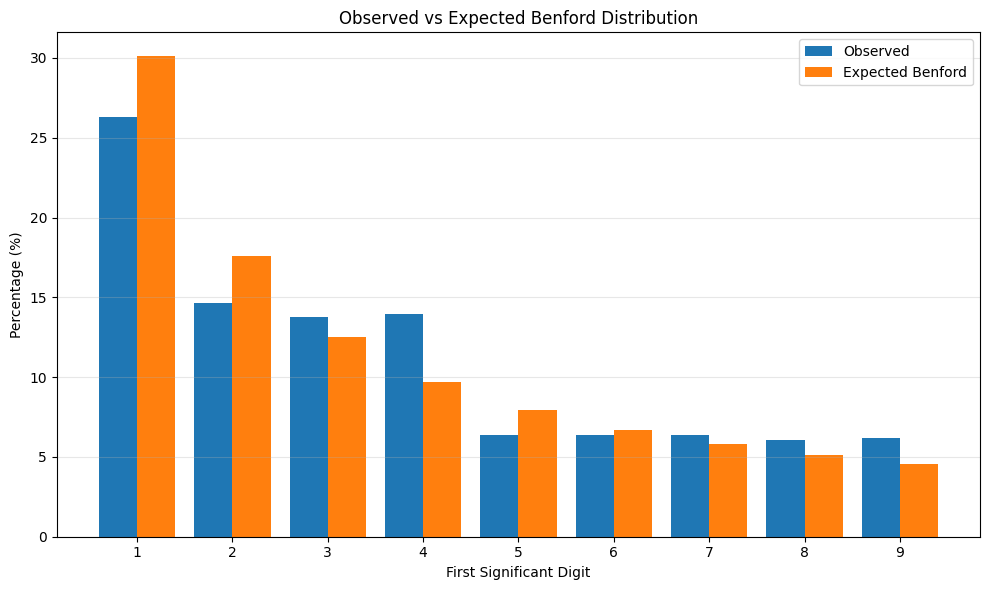

In [ ]:
plt.figure(figsize=(10, 6))

x = benford_analysis["first_digit"]

plt.bar(
    x - 0.2,
    benford_analysis["observed_percentage"],
    width=0.4,
    label="Observed"
)

plt.bar(
    x + 0.2,
    benford_analysis["expected_percentage"],
    width=0.4,
    label="Expected Benford"
)

plt.xlabel("First Significant Digit")
plt.ylabel("Percentage (%)")
plt.title("Observed vs Expected Benford Distribution")
plt.xticks(range(1, 10))
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FA02_PATH,
        "benford_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
largest_deviations = benford_analysis.sort_values(
    "absolute_deviation",
    ascending=False
)

display(largest_deviations)

,first_digit,observed_count,observed_percentage,expected_percentage,absolute_deviation
3,4,20923,13.949225,9.691001,4.258223
0,1,39466,26.311719,30.103000,3.791280
1,2,22002,14.668587,17.609126,2.940539
8,9,9236,6.157580,4.575749,1.581831
4,5,9537,6.358254,7.918125,1.559870
2,3,20646,13.764551,12.493874,1.270677
7,8,9062,6.041575,5.115252,0.926323
6,7,9535,6.356921,5.799195,0.557726
5,6,9587,6.391589,6.694679,0.303090


In [ ]:
benford_analysis.to_csv(
    os.path.join(
        FA02_PATH,
        "benford_analysis.csv"
    ),
    index=False
)

print("Saved:")
print("benford_analysis.csv")
print("benford_distribution.png")

Saved:
benford_analysis.csv
benford_distribution.png


In [ ]:


deviation_mean = benford_analysis["absolute_deviation"].mean()

deviation_digits = benford_analysis[
    benford_analysis["absolute_deviation"] > deviation_mean
]["first_digit"].tolist()

print(
    "Digits with above-average deviation:",
    deviation_digits
)

Digits with above-average deviation: [1, 2, 4]


In [ ]:
benford_flagged = benford_df[
    benford_df["first_digit"].isin(deviation_digits)
].copy()

benford_flagged["benford_flag"] = 1

print("Benford-screened transactions:", len(benford_flagged))
print(
    "Ground-truth fraud among screened:",
    benford_flagged["is_fraud"].sum()
)

Benford-screened transactions: 82391
Ground-truth fraud among screened: 764


In [ ]:
benford_flagged.to_csv(
    os.path.join(
        FA02_PATH,
        "benford_screened_transactions.csv"
    ),
    index=False
)

print("Saved: benford_screened_transactions.csv")

Saved: benford_screened_transactions.csv


In [ ]:
overall_fraud_rate = (
    benford_df["is_fraud"].mean() * 100
)

benford_fraud_rate = (
    benford_flagged["is_fraud"].mean() * 100
)

benford_summary = pd.DataFrame({
    "metric": [
        "Total transactions",
        "Valid positive transactions",
        "Benford MAD (%)",
        "Digits with above-average deviation",
        "Transactions screened",
        "Fraud transactions among screened",
        "Overall fraud rate (%)",
        "Screened transaction fraud rate (%)"
    ],
    "value": [
        len(df),
        len(benford_df),
        mad,
        ", ".join(map(str, deviation_digits)),
        len(benford_flagged),
        int(benford_flagged["is_fraud"].sum()),
        overall_fraud_rate,
        benford_fraud_rate
    ]
})

display(benford_summary)

,metric,value
0,Total transactions,149994
1,Valid positive transactions,149994
2,Benford MAD (%),1.909951
3,Digits with above-average deviation,"1, 2, 4"
4,Transactions screened,82391
5,Fraud transactions among screened,764
6,Overall fraud rate (%),0.966705
7,Screened transaction fraud rate (%),0.927286


In [ ]:
benford_summary.to_csv(
    os.path.join(
        FA02_PATH,
        "benford_summary.csv"
    ),
    index=False
)

print("Saved: benford_summary.csv")

Saved: benford_summary.csv


# FA_02 — Benford's Law Analysis

## Financial Crime Analytics & Money Laundering Investigation Platform

### Objective

This notebook applies Benford's Law to transaction amounts to identify
unusual first-digit distributions that may warrant further forensic
investigation.

### Workflow

1. Load the transaction-level dataset
2. Prepare transaction amounts
3. Extract the first significant digit
4. Calculate observed digit frequencies
5. Calculate expected Benford frequencies
6. Measure deviation using Mean Absolute Deviation (MAD)
7. Visualize observed vs expected distributions
8. Compare Benford-flagged transactions with controlled fraud labels
9. Save forensic analysis outputs

### Important Interpretation

Benford's Law is used as a forensic screening technique.

A deviation from the expected Benford distribution does not by itself
establish fraud or financial misconduct. Additional evidence is required
for investigation.